# Published benchmark results: a first look

- Explore the committed SWE-bench and GAIA leaderboard results offline
- The walkthrough:
  - Check the table and its sources
  - Inspect submission counts and scores within each benchmark
  - Follow the best SWE-bench Verified score over submission dates
- Scores are fractions between 0 and 1
  - SWE-bench measures resolved coding tasks
  - GAIA measures accuracy on reasoning questions
  - The two metrics describe different tasks and are not interchangeable

In [1]:
%load_ext autoreload
%autoreload 2

import logging

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
import helpers.hnotebook as hnotebook

import benchmarking_agents_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpacq7t2r9.json --HistoryManager.hist_file=:memory:


# Part 1: Explore the saved leaderboard table

## Cell 1.1: Load the table and check its provenance

- Run from the project directory so the relative data path resolves
- Gzip compression is detected automatically by `pandas`
- Preserve empty published model names when reading the CSV
- Each row describes one submission at one difficulty
  - The same GAIA submission can contribute up to four rows
  - `date` is the submission date; `retrieved` is the download date

In [3]:
# Read the saved table; no download or API credentials are needed.
scores = pd.read_csv(
    "data/scores.csv.gz",
    keep_default_na=False,
    na_values={"cost_usd": [""]},
)
utils.validate_scores(scores)
print("table_shape=", scores.shape)
display(scores.head())

table_shape= (17594, 13)


,benchmark,split,agent,model_raw,model,task_type,metric,difficulty,score,cost_usd,date,source_url,retrieved
0,gaia,test,AutoGPT4,GPT4 + AutoGPT,gpt4-autogpt,reasoning,accuracy,all,0.049834,NaN,2023-11-03,https://huggingface.co/datasets/gaia-benchmark...,2026-11-23
1,gaia,test,AutoGPT4,GPT4 + AutoGPT,gpt4-autogpt,reasoning,accuracy,level1,0.150538,NaN,2023-11-03,https://huggingface.co/datasets/gaia-benchmark...,2026-11-23
2,gaia,test,AutoGPT4,GPT4 + AutoGPT,gpt4-autogpt,reasoning,accuracy,level2,0.006289,NaN,2023-11-03,https://huggingface.co/datasets/gaia-benchmark...,2026-11-23
3,gaia,test,AutoGPT4,GPT4 + AutoGPT,gpt4-autogpt,reasoning,accuracy,level3,0.000000,NaN,2023-11-03,https://huggingface.co/datasets/gaia-benchmark...,2026-11-23
4,gaia,test,Sibyl System v0.2,GPT-4o,gpt-4o,reasoning,accuracy,all,0.345515,NaN,2023-11-03,https://huggingface.co/datasets/gaia-benchmark...,2026-11-23


In [4]:
# Show the source URLs and retrieval dates stored on the actual table rows.
provenance = scores[["benchmark", "source_url", "retrieved"]]
display(provenance.drop_duplicates().reset_index(drop=True))

,benchmark,source_url,retrieved
0,gaia,https://huggingface.co/datasets/gaia-benchmark...,2026-11-23
1,swe_bench,https://raw.githubusercontent.com/SWE-bench/sw...,2026-11-23


## Cell 1.2: Count rows by benchmark and split

- Count long-format rows separately from overall submission rows
- GAIA difficulty rows explain why its row count exceeds its submissions
- Counts reflect the saved snapshot after exact duplicate removal

In [5]:
# Count every score row in the long-format table.
row_counts = scores.groupby(["benchmark", "split"]).size()
display(row_counts.rename("score_rows").to_frame())

score_rows
benchmark split                   
gaia      test               16888
          validation           383
swe_bench lite                  84
          multilingual          13
          multimodal            22
          test                  24
          verified             180

In [6]:
# Count overall-score submissions without also counting their difficulty rows.
overall = scores.loc[scores["difficulty"] == "all"]
submission_counts = overall.groupby(["benchmark", "split"]).size()
display(submission_counts.rename("overall_submissions").to_frame())

overall_submissions
benchmark split                            
gaia      test                         4226
          validation                     96
swe_bench lite                           84
          multilingual                   13
          multimodal                     22
          test                           24
          verified                      180

## Cell 1.3: Inspect the top 10 SWE-bench Verified submissions

- Rank submissions by their fraction of resolved tasks
- Show both the agent and the published base model
- A model can appear more than once under different submitted systems
- A missing cost means that the leaderboard did not report it

In [7]:
# Select a single benchmark and split before ranking its submissions.
verified = overall.loc[
    (overall["benchmark"] == "swe_bench")
    & (overall["split"] == "verified")
]
top_verified = verified.nlargest(10, "score")
display(top_verified[["agent", "model_raw", "score", "cost_usd", "date"]])

,agent,model_raw,score,cost_usd,date
17574,Sonar Foundation Agent,Claude 4.5 Opus,0.792,NaN,2025-12-05
17580,live-SWE-agent,Claude 4.5 Opus,0.792,NaN,2025-12-15
17555,TRAE,Doubao-Seed-Code,0.788,NaN,2025-09-28
17567,live-SWE-agent,Gemini 3 Pro Preview,0.774,NaN,2025-11-20
17537,EPAM AI/Run Developer Agent,Claude 4 Sonnet,0.768,NaN,2025-08-04
17552,Atlassian Rovo Dev,Multiple,0.768,NaN,2025-09-02
17581,mini-SWE-agent,Claude 4.5 Opus,0.768,376.953999,2026-02-17
17547,ACoder,Multiple,0.764,NaN,2025-08-19
17582,mini-SWE-agent,Gemini 3 Flash,0.758,177.982065,2026-02-17
17583,mini-SWE-agent,MiniMax M2.5,0.758,36.644994,2026-02-17


## Cell 1.4: Compare GAIA test scores across difficulties

- Compute the mean published submission score for each difficulty
- Include the number of contributing submissions beside each mean
- Missing level scores were skipped by the loader
  - Difficulty groups can therefore have different sample sizes
- These are submission averages, not a question-weighted benchmark score
- An unknown model family still represents a valid published submission

In [8]:
# Summarize test submissions separately for each GAIA difficulty.
gaia_test = scores.loc[
    (scores["benchmark"] == "gaia") & (scores["split"] == "test")
]
gaia_summary = gaia_test.groupby("difficulty").agg(
    mean_score=("score", "mean"),
    n_submissions=("score", "size"),
)
display(gaia_summary.reindex(["all", "level1", "level2", "level3"]))

,mean_score,n_submissions
difficulty,,
all,0.280981,4226
level1,0.320167,4219
level2,0.272055,4221
level3,0.231895,4222


## Cell 1.5: Follow the best SWE-bench Verified score over time

**Goal**

- See how the best recorded overall score changes by submission date

**Description**

- Input: the saved table filtered to SWE-bench Verified overall scores
- Panel: cumulative best score, on a fixed 0 to 1 scale
- The line stays flat when a later submission has a lower score

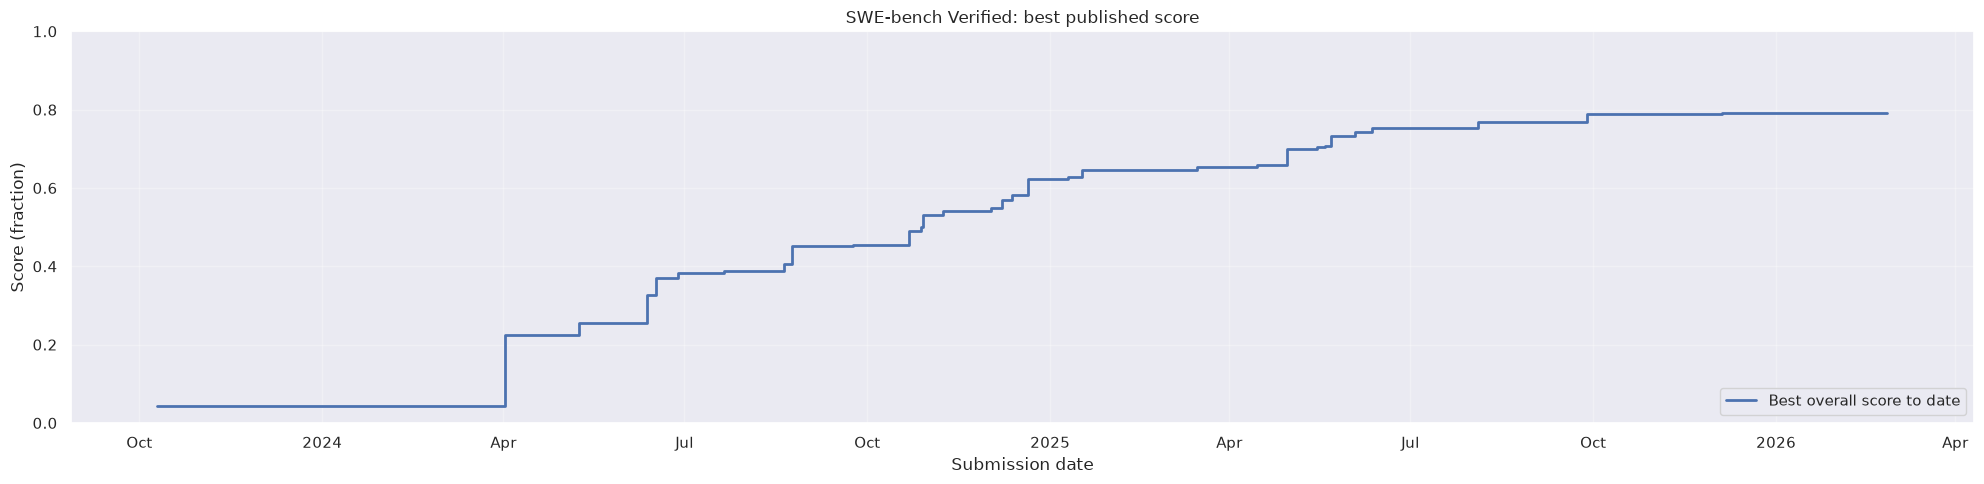

In [9]:
# Draw the curve using the tested utility rather than inline plotting logic.
ax = utils.plot_best_score_over_time(
    scores, benchmark="swe_bench", split="verified"
)
plt.show()

**Interpretation**

- Read upward steps as improvements among the recorded submissions
- Flat sections mean no improvement among those submissions
  - They do not establish that research progress stopped
- The history is reconstructed from dates in one saved leaderboard snapshot
  - It is not a collection of daily historical leaderboard snapshots

**Implementation** `plot_best_score_over_time()`

- Selects the requested benchmark and split at overall difficulty
- Takes the maximum score on each submission date
- Sorts dates and plots their cumulative maximum

## Next steps

- Keep comparisons within each benchmark until model aliases are curated
- Use the API notebook for the schema and loader walkthrough
- next: MLE-bench, DSBench, model aliases (PR 2)